SVM -> Support Vector Machines

can perfrom both classification and regression

updated version of logistic regression


has three parallel lines

one best fit line and two marginal line


the main goal is to find the best seperator line

choose the max margin(distance between marginal planes)

the first data points that are in contact to marginal lines are called support vectors

SVC -> Support Vector Classifier

SVR -> Support Vector Regressor

Soft Margin -> Some amount of error

Hard Margin -> No overlapping

In [137]:
import pandas as pd
import numpy as np
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.svm import SVC,SVR
from sklearn.metrics import classification_report,confusion_matrix,r2_score
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer

SVC

In [138]:
X,Y=make_classification(n_samples=1000,n_features=2,n_classes=2,n_clusters_per_class=1,n_redundant=0)

In [139]:
X

array([[-2.00282884e-01, -9.16156910e-01],
       [-6.39065606e-01, -1.04918688e+00],
       [-4.55095182e-01, -1.29914678e+00],
       [ 2.88662844e-01, -6.51050390e-01],
       [ 6.46219067e-01,  1.47526371e+00],
       [ 1.93960828e+00,  6.97302092e-01],
       [-1.56108792e+00, -1.06117191e+00],
       [ 4.71353564e-01,  6.87725788e-01],
       [ 1.72894787e+00,  7.51597155e-01],
       [ 2.08615393e-01,  1.48619823e+00],
       [-1.35020806e+00, -9.81233625e-01],
       [ 8.62649731e-01,  1.68624124e+00],
       [ 9.07597286e-01,  1.24468432e+00],
       [ 1.92506700e+00, -8.57051645e-01],
       [-6.82527584e-01, -1.45139982e-01],
       [-1.67349062e+00, -7.79005708e-01],
       [ 1.85703195e+00,  1.50150606e+00],
       [ 8.97476226e-01,  1.27648395e+00],
       [ 8.34890046e-01,  4.42942720e-01],
       [-1.09281772e-01,  1.94020923e+00],
       [ 3.08884147e-01, -1.64260417e+00],
       [ 7.87488141e-01,  2.00136821e+00],
       [ 7.46587036e-01,  3.22865171e-01],
       [ 1.

In [140]:
Y

array([0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,

<Axes: >

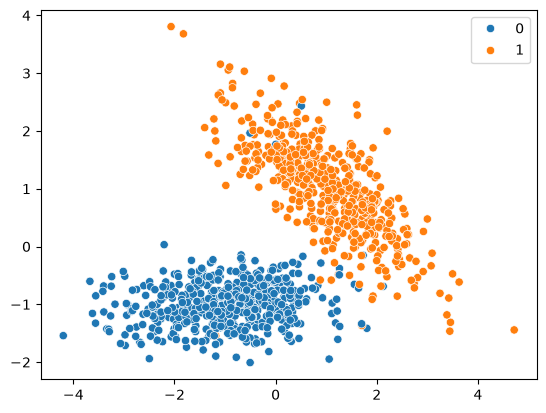

In [141]:
sns.scatterplot(x=X[:,0],y=X[:,1],hue=Y)

In [142]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=43)

In [143]:
model=SVC(kernel='linear')
model

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [144]:
model.fit(X_train,Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [145]:
Y_pred=model.predict(X_test)

In [146]:
Y_train_pred=model.predict(X_train)

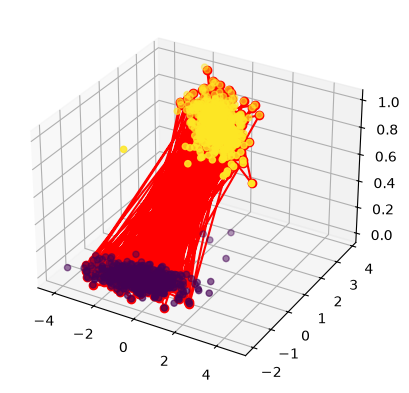

In [147]:
fig=plt.figure()
ax=fig.add_subplot(projection='3d')
ax.scatter(X[:,0],X[:,1],Y,c=Y)
ax.plot(X_train[:,0],X_train[:,1],Y_train_pred,c="red",marker='o')
plt.show()

In [148]:
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))

[[161   4]
 [  1 134]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       165
           1       0.97      0.99      0.98       135

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



In [149]:
print(confusion_matrix(Y_train,Y_train_pred))
print(classification_report(Y_train,Y_train_pred))

[[331   7]
 [  3 359]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       338
           1       0.98      0.99      0.99       362

    accuracy                           0.99       700
   macro avg       0.99      0.99      0.99       700
weighted avg       0.99      0.99      0.99       700



In [150]:
rbf=SVC(kernel='rbf')
rbf.fit(X_train,Y_train)
Y_pred=rbf.predict(X_test)
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))

[[161   4]
 [  1 134]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       165
           1       0.97      0.99      0.98       135

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



In [151]:
polynomial=SVC(kernel='poly')
polynomial.fit(X_train,Y_train)
Y_pred=polynomial.predict(X_test)
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))

[[161   4]
 [  5 130]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       165
           1       0.97      0.96      0.97       135

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [152]:
sigmoid=SVC(kernel='sigmoid')
sigmoid.fit(X_train,Y_train)
Y_pred=sigmoid.predict(X_test)
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))

[[153  12]
 [  7 128]]
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       165
           1       0.91      0.95      0.93       135

    accuracy                           0.94       300
   macro avg       0.94      0.94      0.94       300
weighted avg       0.94      0.94      0.94       300



In [153]:
parameters={
    'C':[0.1,1,10,100,1000],
    'gamma':[1,0.1,0.01,0.001,0.0001,'scale','auto'],
    'kernel':['rbf','linear','sigmoid','poly']
}

In [154]:
model=SVC()

In [155]:
gird=GridSearchCV(model,param_grid=parameters,refit=True,cv=5,verbose=3)

In [156]:
gird.fit(X_train,Y_train)

Fitting 5 folds for each of 140 candidates, totalling 700 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.993 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.964 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.971 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.993 total time=   0.0s


[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.986 total time=   0.0s
[CV 1/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.993 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.964 total time=   0.0s
[CV 3/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.971 total time=   0.0s
[CV 4/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.993 total time=   0.0s
[CV 5/5] END .....C=0.1, gamma=1, kernel=linear;, score=1.000 total time=   0.0s
[CV 1/5] END ....C=0.1, gamma=1, kernel=sigmoid;, score=0.950 total time=   0.0s
[CV 2/5] END ....C=0.1, gamma=1, kernel=sigmoid;, score=0.936 total time=   0.0s
[CV 3/5] END ....C=0.1, gamma=1, kernel=sigmoid;, score=0.971 total time=   0.0s
[CV 4/5] END ....C=0.1, gamma=1, kernel=sigmoid;, score=0.979 total time=   0.0s
[CV 5/5] END ....C=0.1, gamma=1, kernel=sigmoid;, score=0.964 total time=   0.0s
[CV 1/5] END .......C=0.1, gamma=1, kernel=poly;, score=0.993 total time=   0.0s
[CV 2/5] END .......C=0.1, g

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf', 'linear', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a

In [157]:
Y_pred=gird.predict(X_test)

In [158]:
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))

[[161   4]
 [  1 134]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       165
           1       0.97      0.99      0.98       135

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



SVR

In [159]:
df=sns.load_dataset('tips')

In [160]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [161]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [162]:
df['sex'].value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

In [163]:
X=df.drop('total_bill',axis=1)
Y=df['total_bill']

In [164]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.25,random_state=43)

In [165]:
le1=LabelEncoder()
le2=LabelEncoder()
le3=LabelEncoder()

In [166]:
X_train.head()

,tip,sex,smoker,day,time,size
210,2.00,Male,Yes,Sat,Dinner,3
211,5.16,Male,Yes,Sat,Dinner,4
229,2.88,Female,Yes,Sat,Dinner,2
147,1.63,Female,No,Thur,Lunch,2
136,2.00,Female,No,Thur,Lunch,2


In [167]:
X_train['sex']=le1.fit_transform(X_train['sex'])
X_train['smoker']=le2.fit_transform(X_train['smoker'])
X_train['time']=le3.fit_transform(X_train['time'])

In [168]:
X_test['sex']=le1.transform(X_test['sex'])
X_test['smoker']=le2.transform(X_test['smoker'])
X_test['time']=le3.transform(X_test['time'])

In [169]:
X_train.head()

,tip,sex,smoker,day,time,size
210,2.00,1,1,Sat,0,3
211,5.16,1,1,Sat,0,4
229,2.88,0,1,Sat,0,2
147,1.63,0,0,Thur,1,2
136,2.00,0,0,Thur,1,2


In [170]:
X_test.head()

,tip,sex,smoker,day,time,size
55,3.51,1,0,Sun,0,2
94,3.25,0,0,Fri,0,2
96,4.00,1,1,Fri,0,2
54,4.34,1,0,Sun,0,4
90,3.00,1,1,Fri,0,2


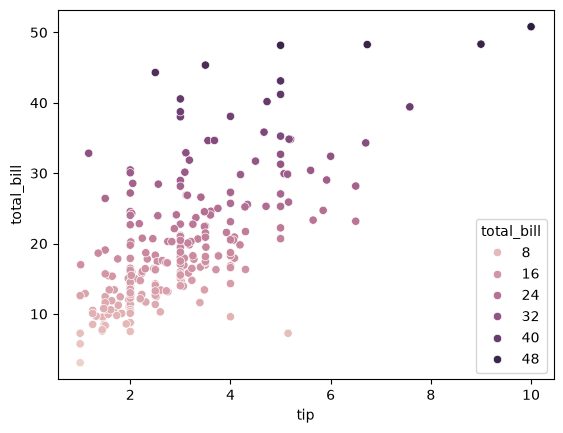

In [171]:
sns.scatterplot(x=X['tip'],y=Y,hue=Y)
plt.show()

In [172]:
ct=ColumnTransformer(transformers=[('onehot',OneHotEncoder(drop='first'),[3])],remainder='passthrough')

In [173]:
np.set_printoptions(threshold=sys.maxsize)
X_train=ct.fit_transform(X_train)
print(X_train)

[[ 1.    0.    0.    2.    1.    1.    0.    3.  ]
 [ 1.    0.    0.    5.16  1.    1.    0.    4.  ]
 [ 1.    0.    0.    2.88  0.    1.    0.    2.  ]
 [ 0.    0.    1.    1.63  0.    0.    1.    2.  ]
 [ 0.    0.    1.    2.    0.    0.    1.    2.  ]
 [ 0.    0.    1.    2.    1.    1.    1.    2.  ]
 [ 0.    0.    1.    3.    1.    0.    1.    2.  ]
 [ 0.    1.    0.    6.5   1.    1.    0.    4.  ]
 [ 0.    0.    0.    2.5   0.    1.    0.    2.  ]
 [ 1.    0.    0.    3.35  1.    0.    0.    3.  ]
 [ 1.    0.    0.    3.09  0.    1.    0.    4.  ]
 [ 0.    0.    1.    1.83  0.    0.    1.    1.  ]
 [ 0.    1.    0.    2.54  1.    0.    0.    2.  ]
 [ 1.    0.    0.    3.    1.    1.    0.    5.  ]
 [ 1.    0.    0.    1.64  1.    1.    0.    2.  ]
 [ 0.    1.    0.    3.23  1.    0.    0.    2.  ]
 [ 0.    1.    0.    1.66  1.    0.    0.    3.  ]
 [ 0.    0.    0.    1.5   1.    1.    0.    2.  ]
 [ 1.    0.    0.    3.48  0.    1.    0.    2.  ]
 [ 1.    0.    0.    3.    0.  

In [174]:
X_test=ct.transform(X_test)

In [175]:
X_test

array([[0.  , 1.  , 0.  , 3.51, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 3.25, 0.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 4.  , 1.  , 1.  , 0.  , 2.  ],
       [0.  , 1.  , 0.  , 4.34, 1.  , 0.  , 0.  , 4.  ],
       [0.  , 0.  , 0.  , 3.  , 1.  , 1.  , 0.  , 2.  ],
       [0.  , 1.  , 0.  , 5.  , 1.  , 0.  , 0.  , 6.  ],
       [0.  , 0.  , 0.  , 1.58, 1.  , 1.  , 1.  , 2.  ],
       [0.  , 1.  , 0.  , 1.71, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 4.3 , 0.  , 1.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 2.18, 1.  , 0.  , 1.  , 3.  ],
       [1.  , 0.  , 0.  , 2.72, 1.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 1.5 , 1.  , 0.  , 1.  , 2.  ],
       [1.  , 0.  , 0.  , 3.  , 0.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 1.  , 2.5 , 1.  , 0.  , 1.  , 2.  ],
       [1.  , 0.  , 0.  , 2.47, 0.  , 0.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 3.  , 1.  , 1.  , 0.  , 2.  ],
       [0.  , 0.  , 0.  , 2.  , 0.  , 1.  , 1.  , 2.  ],
       [0.  , 1.  , 0.  , 3.71,

In [176]:
model=SVR()
model

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [177]:
model.fit(X_train,Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [178]:
Y_pred=model.predict(X_test)

In [179]:
print(r2_score(Y_test,Y_pred))

0.3760300943824072


In [180]:
grid=GridSearchCV(SVR(),param_grid=parameters,refit=True,verbose=3)

In [ ]:
grid.fit(X_train,Y_train)

Fitting 5 folds for each of 140 candidates, totalling 700 fits
[CV 1/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.097 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.003 total time=   0.0s
[CV 3/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.107 total time=   0.0s
[CV 4/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.116 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.041 total time=   0.0s
[CV 1/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.383 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.659 total time=   0.0s
[CV 3/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.546 total time=   0.0s
[CV 4/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.339 total time=   0.0s
[CV 5/5] END .....C=0.1, gamma=1, kernel=linear;, score=0.410 total time=   0.0s
[CV 1/5] END ...C=0.1, gamma=1, kernel=sigmoid;, score=-0.143 total time=   0.0s
[CV 2/5] END ...C=0.1, gamma=1, kernel=sigmoid

In [ ]:
Y_pred=grid.predict(X_test)

In [ ]:
print(r2_score(Y_test,Y_pred))